# Hybrid Sampling

## 1. What is hybrid sampling?

Hybrid sampling combines oversampling and undersampling in a single workflow.

- Oversampling: increases representation of the minority class, either by duplicating existing examples or synthesizing new ones.

- Undersampling: removes some majority-class examples to reduce imbalance.

__Why combine them?__
 Oversampling alone can make the training set unnecessarily large or add synthetic points in noisy regions. Undersampling alone can discard useful information about the majority class. A hybrid method tries to balance these trade-offs.

### 1. SMOTE + Tomek Links

SMOTE creates synthetic minority-class examples. Tomek Links then identifies certain closely neighboring points from opposite classes and removes points according to the chosen cleaning strategy, commonly the majority-class member.

Purpose: improve minority representation and clean overlapping class boundaries.

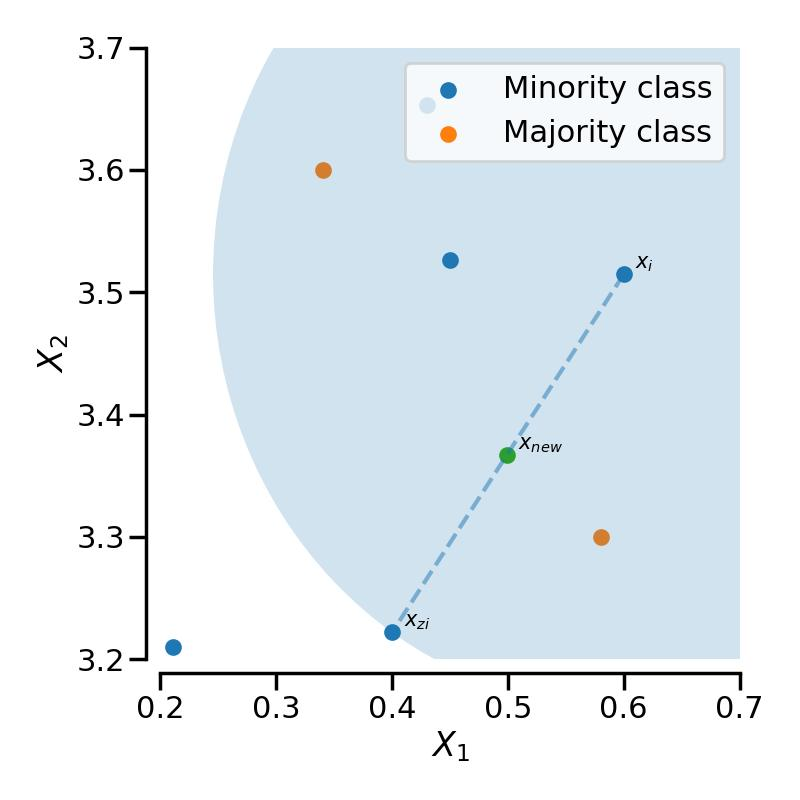

2. SMOTE + ENN (SMOTEENN)

SMOTE creates synthetic minority examples. Edited Nearest Neighbours (ENN) removes samples whose labels disagree with their neighboring labels, using a neighborhood rule.

Purpose: rebalance the data and apply more aggressive cleaning of noisy or overlapping regions.

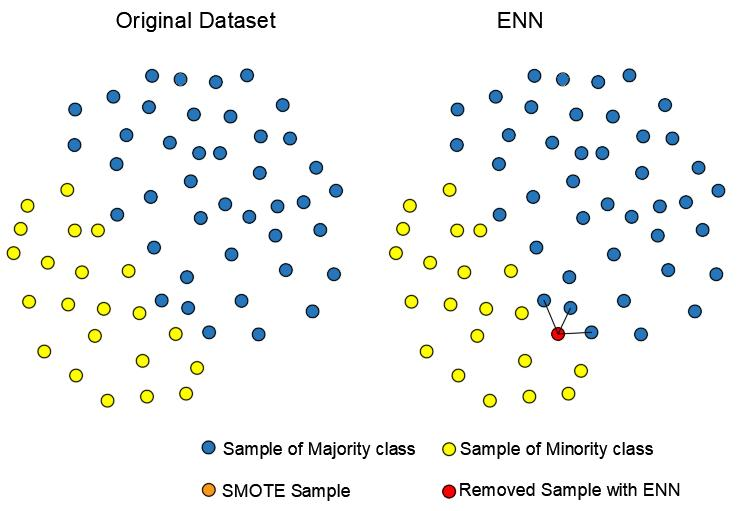

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    average_precision_score
)

In [15]:
sns.set_theme(style="whitegrid")

In [16]:
# Generate an imbalanced binary classification dataset
X, y = make_classification(
    n_samples=2000,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    weights=[0.95, 0.05],
    class_sep=0.8,
    flip_y=0.01,
    random_state=42
)

df = pd.DataFrame(X, columns=["Feature 1", "Feature 2"])
df["Target"] = y

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["Target"].value_counts().sort_index())
print("\nClass percentages:")
print((df["Target"].value_counts(normalize=True) * 100).round(2))

Dataset shape: (2000, 3)

Class distribution:
Target
0    1893
1     107
Name: count, dtype: int64

Class percentages:
Target
0    94.65
1     5.35
Name: proportion, dtype: float64


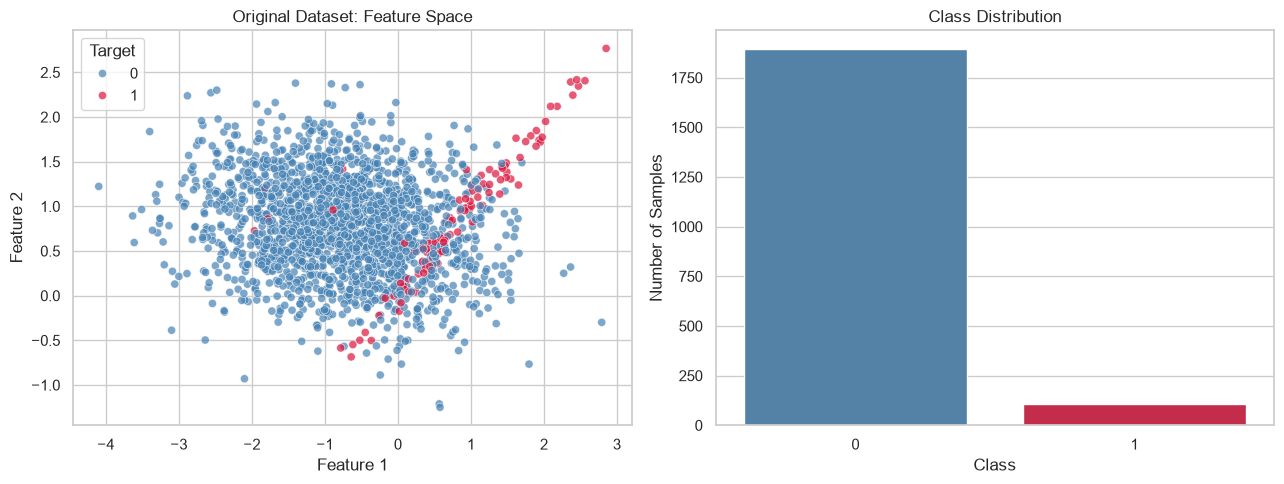

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Scatter plot
sns.scatterplot(
    data=df,
    x="Feature 1",
    y="Feature 2",
    hue="Target",
    palette={0: "steelblue", 1: "crimson"},
    alpha=0.7,
    s=35,
    ax=axes[0]
)
axes[0].set_title("Original Dataset: Feature Space")

# Class counts
sns.countplot(
    data=df,
    x="Target",
    hue="Target",
    palette={0: "steelblue", 1: "crimson"},
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Class Distribution")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Number of Samples")

plt.tight_layout()
plt.show()

## Baseline Model

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTest distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training distribution:
0    1420
1      80
Name: count, dtype: int64

Test distribution:
0    473
1     27
Name: count, dtype: int64


BASELINE CLASSIFICATION REPORT
              precision    recall  f1-score   support

Majority (0)      0.949     0.989     0.969       473
Minority (1)      0.286     0.074     0.118        27

    accuracy                          0.940       500
   macro avg      0.618     0.532     0.543       500
weighted avg      0.913     0.940     0.923       500

Baseline Average Precision: 0.241


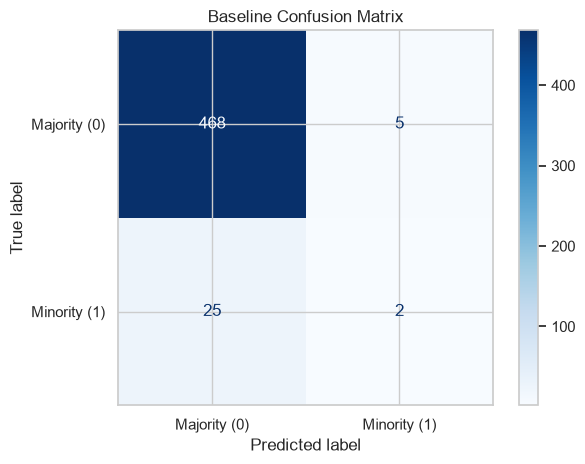

In [20]:
baseline_model = LogisticRegression(max_iter=1000, random_state=42)
baseline_model.fit(X_train_scaled, y_train)

baseline_pred = baseline_model.predict(X_test_scaled)
baseline_proba = baseline_model.predict_proba(X_test_scaled)[:, 1]

print("BASELINE CLASSIFICATION REPORT")
print(classification_report(
    y_test, baseline_pred,
    target_names=["Majority (0)", "Minority (1)"],
    digits=3,
    zero_division=0
))

print("Baseline Average Precision:",
      round(average_precision_score(y_test, baseline_proba), 3))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    baseline_pred,
    display_labels=["Majority (0)", "Minority (1)"],
    cmap="Blues"
)
plt.title("Baseline Confusion Matrix")
plt.tight_layout()
plt.show()

## Using Hybrid Sampling SMOTETOMEK

In [21]:
from imblearn.combine import SMOTETomek

sampler = SMOTETomek(random_state=42)

X_train_resampled, y_train_resampled = sampler.fit_resample(
    X_train_scaled,
    y_train
)

print("Before SMOTETomek:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nAfter SMOTETomek:")
print(pd.Series(y_train_resampled).value_counts().sort_index())

Before SMOTETomek:
0    1420
1      80
Name: count, dtype: int64

After SMOTETomek:
0    1393
1    1393
Name: count, dtype: int64


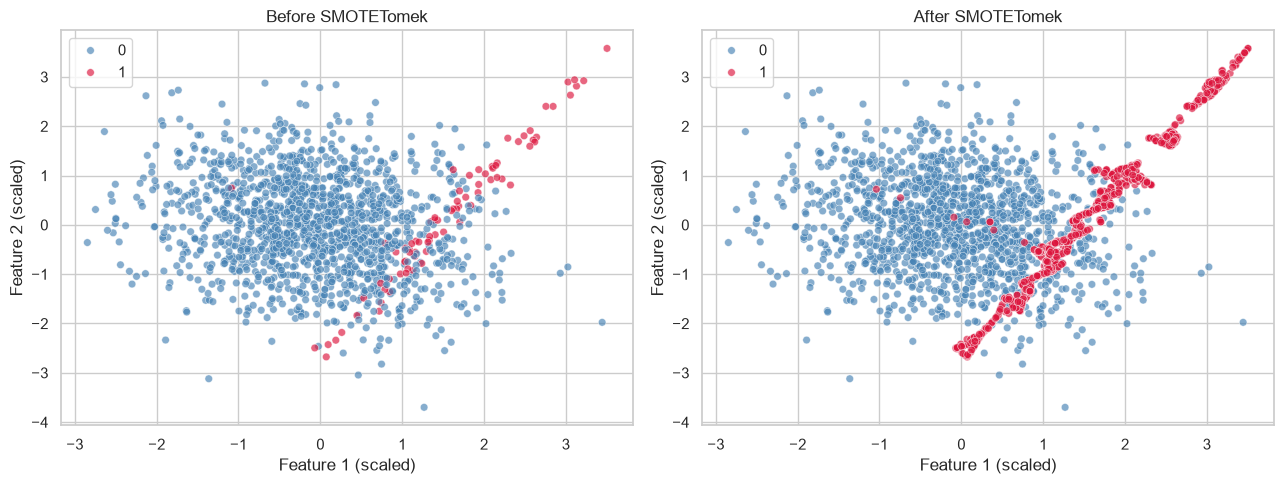

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Before resampling
sns.scatterplot(
    x=X_train_scaled[:, 0],
    y=X_train_scaled[:, 1],
    hue=y_train,
    palette={0: "steelblue", 1: "crimson"},
    alpha=0.65,
    s=30,
    ax=axes[0]
)
axes[0].set_title("Before SMOTETomek")
axes[0].set_xlabel("Feature 1 (scaled)")
axes[0].set_ylabel("Feature 2 (scaled)")

# After resampling
sns.scatterplot(
    x=X_train_resampled[:, 0],
    y=X_train_resampled[:, 1],
    hue=y_train_resampled,
    palette={0: "steelblue", 1: "crimson"},
    alpha=0.65,
    s=30,
    ax=axes[1]
)
axes[1].set_title("After SMOTETomek")
axes[1].set_xlabel("Feature 1 (scaled)")
axes[1].set_ylabel("Feature 2 (scaled)")

plt.tight_layout()
plt.show()

SMOTETOMEK CLASSIFICATION REPORT
              precision    recall  f1-score   support

Majority (0)      0.990     0.808     0.889       473
Minority (1)      0.202     0.852     0.326        27

    accuracy                          0.810       500
   macro avg      0.596     0.830     0.608       500
weighted avg      0.947     0.810     0.859       500

SMOTETomek Average Precision: 0.157


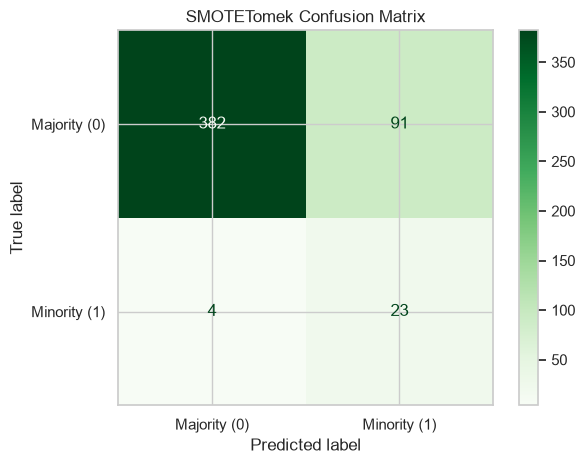

In [23]:
hybrid_model = LogisticRegression(max_iter=1000, random_state=42)

hybrid_model.fit(X_train_resampled, y_train_resampled)

hybrid_pred = hybrid_model.predict(X_test_scaled)
hybrid_proba = hybrid_model.predict_proba(X_test_scaled)[:, 1]

print("SMOTETOMEK CLASSIFICATION REPORT")
print(classification_report(
    y_test, hybrid_pred,
    target_names=["Majority (0)", "Minority (1)"],
    digits=3,
    zero_division=0
))

print("SMOTETomek Average Precision:",
      round(average_precision_score(y_test, hybrid_proba), 3))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    hybrid_pred,
    display_labels=["Majority (0)", "Minority (1)"],
    cmap="Greens"
)
plt.title("SMOTETomek Confusion Matrix")
plt.tight_layout()
plt.show()

            Accuracy  Minority Precision  Minority Recall  Minority F1  \
Model                                                                    
Baseline        0.94               0.286            0.074        0.118   
SMOTETomek      0.81               0.202            0.852        0.326   

            Average Precision  
Model                          
Baseline                0.241  
SMOTETomek              0.157  


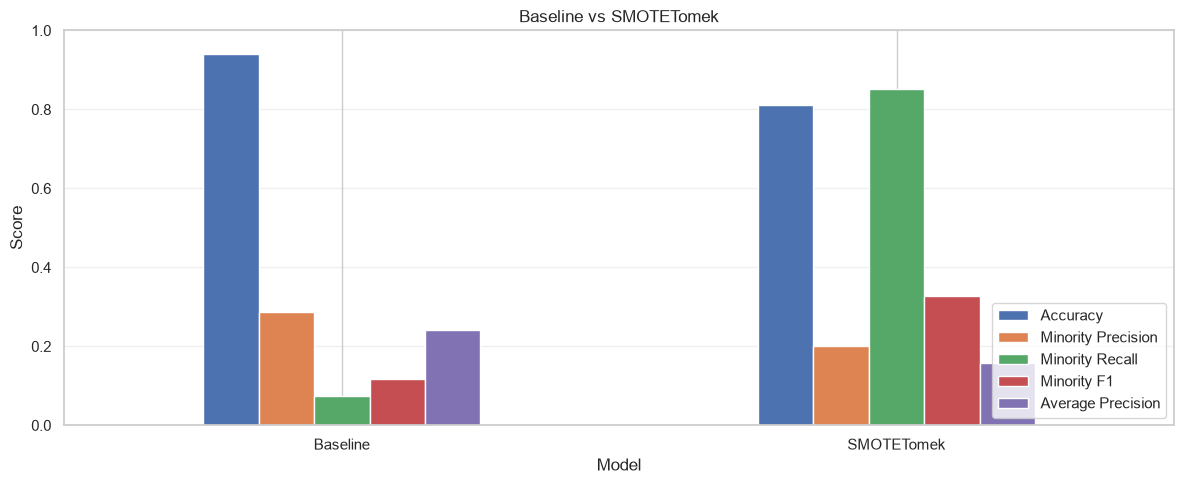

In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

def get_metrics(y_true, y_pred, y_proba, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Minority Precision": precision_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "Minority Recall": recall_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "Minority F1": f1_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "Average Precision": average_precision_score(y_true, y_proba)
    }

comparison = pd.DataFrame([
    get_metrics(
        y_test, baseline_pred, baseline_proba, "Baseline"
    ),
    get_metrics(
        y_test, hybrid_pred, hybrid_proba, "SMOTETomek"
    )
]).set_index("Model")

print(comparison.round(3))

comparison.drop(columns=[]).plot(
    kind="bar",
    figsize=(12, 5),
    ylim=(0, 1),
    rot=0
)
plt.title("Baseline vs SMOTETomek")
plt.ylabel("Score")
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

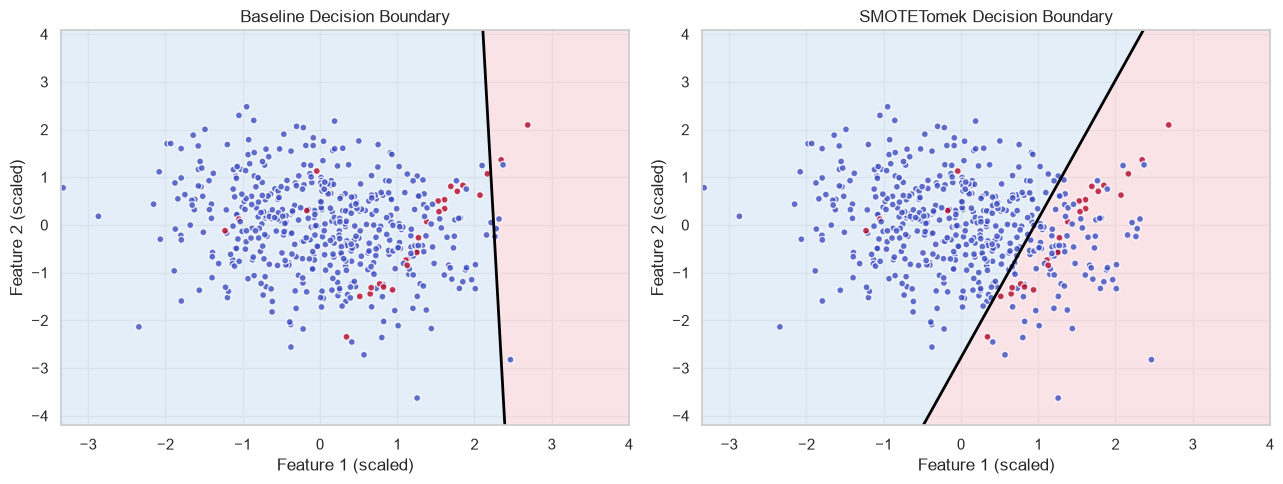

In [25]:
def plot_decision_boundary(model, ax, title):
    x_min, x_max = X_train_scaled[:, 0].min() - 0.5, X_train_scaled[:, 0].max() + 0.5
    y_min, y_max = X_train_scaled[:, 1].min() - 0.5, X_train_scaled[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    probabilities = model.predict_proba(grid)[:, 1].reshape(xx.shape)

    ax.contourf(
        xx, yy, probabilities,
        levels=[0, 0.5, 1],
        colors=["#DCEAF7", "#F8DDE2"],
        alpha=0.8
    )
    ax.contour(
        xx, yy, probabilities,
        levels=[0.5],
        colors="black",
        linewidths=2
    )

    ax.scatter(
        X_test_scaled[:, 0],
        X_test_scaled[:, 1],
        c=y_test,
        cmap="coolwarm",
        edgecolors="white",
        s=25,
        alpha=0.8
    )

    ax.set_title(title)
    ax.set_xlabel("Feature 1 (scaled)")
    ax.set_ylabel("Feature 2 (scaled)")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plot_decision_boundary(
    baseline_model, axes[0], "Baseline Decision Boundary"
)

plot_decision_boundary(
    hybrid_model, axes[1], "SMOTETomek Decision Boundary"
)

plt.tight_layout()
plt.show()

## Production Grade Imblearn Pipeline

In [26]:
from imblearn.pipeline import Pipeline
from imblearn.combine import SMOTETomek
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

smotetomek_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("sampler", SMOTETomek(random_state=42)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

# Fit on original training data
smotetomek_pipeline.fit(X_train, y_train)

# Predict on original, untouched test data
pipeline_pred = smotetomek_pipeline.predict(X_test)
pipeline_proba = smotetomek_pipeline.predict_proba(X_test)[:, 1]

print("PIPELINE CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    pipeline_pred,
    target_names=["Majority (0)", "Minority (1)"],
    digits=3,
    zero_division=0
))

print("Pipeline Average Precision:",
      round(average_precision_score(y_test, pipeline_proba), 3))

PIPELINE CLASSIFICATION REPORT
              precision    recall  f1-score   support

Majority (0)      0.990     0.808     0.889       473
Minority (1)      0.202     0.852     0.326        27

    accuracy                          0.810       500
   macro avg      0.596     0.830     0.608       500
weighted avg      0.947     0.810     0.859       500

Pipeline Average Precision: 0.157


### Point to Note

1. SKlearn does not support resampling techniques. It expexts the number of samples to be same before and after transformations.

2. We need Imblearn Pipeline that can accomodate resampling technique along with basic transformations.

3. We have use this technqiue especially when we are doing cross validation and hyperparameter, this approach will prevent data leakage.

__What the imblearn pipeline does__

In every round of cross-validation, it:

Takes only the training folds

Applies resampling to them

Trains the model

Evaluates on the untouched validation fold (no resampling)